# Notebook 7 (optional) — 2D or 3D? Testing a design choice
**Lab IA & CD – Project 1 | Lung Nodule Malignancy on CT (LNDb + LIDC-IDRI)**

---

## The question
A CT scan is a stack of 2D slices, i.e. a 3D volume. Many radiomics studies describe a nodule on a
**single slice** — the one where it is largest, as a radiologist measures it. This project describes
it in **3D**: the whole nodule, resampled to 1 × 1 × 1 mm voxels. The project brief asks to discuss
this choice (*"2D vs 3D solution"*). Here we argue it, and then **test it**.

## Why we expected 3D to be better
| | 2D (largest slice) | 3D (whole nodule) — our choice |
|---|---|---|
| **What is described** | One cross-section | The whole nodule |
| **Shape** | Area and outline of one slice | Volume, sphericity, true 3D surface |
| **Texture** | ~hundreds of pixels | ~thousands of voxels → more stable statistics |
| **Part-solid nodules** | The solid core may not be on the chosen slice | The core is always inside the volume |
| **Nodule vs vessel** | A vessel cut across looks like a nodule | A vessel continues across slices; a nodule ends |
| **Thick slices (2.5–5 mm)** | Unaffected | Interpolated in z — a possible weakness of 3D |
| **Cost** | Fast | Slower (still minutes on a laptop) |

## How we test it — a fair comparison
Only **one thing** changes between the two arms:

| Kept identical | Changes |
|---|---|
| The same 1633 LIDC-IDRI nodules (the largest labelled set, 5 folds by patient), the same automatic 3D segmentation | **2D**: features of the axial slice where the segmentation is largest (759 features) |
| The same model (the score committee of Notebooks 4 and 6, prevalence cut-offs) and hyper-parameter search | **3D**: features of the whole segmented volume (1136 features) |
| The same 5 outer folds, grouped by patient, and the same four competition metrics | |

**Inputs:** `outputs/features_lidc.csv`, `outputs/lidc_nodules.csv` (Notebook 5), the LIDC images,
`outputs/selected_features.json` (Notebook 3)
**Output:** `outputs/features_lidc_2d.csv`

> ⏱️ Run time: ~3 min for the 2D features + ~20 min for the two cross-validations (8-core laptop).

---

## 1. Setup

In [1]:
import json
import shutil
import tempfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Memory
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score, f1_score, mean_absolute_error
from sklearn.model_selection import StratifiedGroupKFold

import lndb_utils as U
import lndb_models as M
import lidc_data as L

for w in (UserWarning, RuntimeWarning, FutureWarning, ConvergenceWarning, pd.errors.PerformanceWarning):
    warnings.filterwarnings('ignore', category=w)
plt.rcParams.update(U.PLOT_STYLE)

N_JOBS = -1
OUTER_SPLITS = 5                        # 5 folds grouped by patient
MAL_THRESHOLDS = (1.5, 2.5, 3.5, 4.5)
LABELS = np.arange(1, 6)
CACHE_DIR = tempfile.mkdtemp(prefix='lndb_nb7_')
memory = Memory(CACHE_DIR, verbose=0)
ARM_COLORS = {'2D': '#9aa0b4', '3D': U.COLOR_ACCENT}
print('Setup complete.')

Setup complete.


## 2. The two feature sets
The 3D features come from Notebook 5. The 2D features are extracted here with the same crop and the
same segmentation, keeping only the axial slice where the segmented nodule is largest
(`lndb_features.features_2d`): pyradiomics in 2D (shape of the outline, in-plane wavelets and LoG)
plus the composition features measured on that slice.

In [2]:
lidc3d = pd.read_csv(U.OUTPUT_DIR / 'features_lidc.csv')
nodules = pd.read_csv(U.OUTPUT_DIR / 'lidc_nodules.csv')
keys = ['patient_id', 'scan_id', 'nodule_id']
nodules = nodules.merge(lidc3d[keys], on=keys)                       # the nodules with 3D features

f2d = L.extract_features(nodules, n_jobs=N_JOBS, dims=2)
lidc = lidc3d.merge(f2d.drop(columns=['seg_status', 'error'], errors='ignore'), on=keys, how='left',
                    validate='one_to_one')

features_3d = [c for c in lidc3d.columns if c.startswith(('rad_', 'comp_'))]
features_2d = [c for c in lidc.columns if c.startswith(('r2d_', 'c2d_'))]
lidc[keys + features_2d].to_csv(U.OUTPUT_DIR / 'features_lidc_2d.csv', index=False)

print(f'Nodules: {len(lidc)}  |  3D features: {len(features_3d)}  |  2D features: {len(features_2d)}')
print(f'Nodules whose 2D extraction failed (filled by the imputer): {lidc[features_2d].isna().all(axis=1).sum()}')

Nodules: 1633  |  3D features: 1136  |  2D features: 759
Nodules whose 2D extraction failed (filled by the imputer): 0


## 3. Same model, same folds — 2D vs 3D
The score committee (prevalence cut-offs) is trained and evaluated with nested cross-validation on
each feature set, on LIDC-IDRI — the largest set of nodules with malignancy ratings, which makes the
comparison as precise as possible. The same 5 outer folds, grouped by patient, are used for both arms.

In [3]:
selection = json.loads((U.OUTPUT_DIR / 'selected_features.json').read_text())
score = lidc['malignancy_mean'].values
y = lidc['malignancy_class'].values
groups = lidc['patient_id'].values
fold = np.zeros(len(lidc), dtype=int)
for k, (_, te) in enumerate(StratifiedGroupKFold(OUTER_SPLITS, shuffle=True, random_state=U.RANDOM_STATE)
                            .split(np.zeros(len(y)), y, groups)):
    fold[te] = k


def metrics(y_true, y_pred):
    return {'Balanced acc.': balanced_accuracy_score(y_true, y_pred),
            'Macro F1': f1_score(y_true, y_pred, labels=LABELS, average='macro', zero_division=0),
            'QWK': cohen_kappa_score(y_true, y_pred, weights='quadratic'),
            'MAE': mean_absolute_error(y_true, y_pred)}


def run_arm(X):
    pred = np.zeros(len(y), dtype=int)
    for k in range(OUTER_SPLITS):
        tr, te = fold != k, fold == k
        model = M.TextureScoreCommittee(selection=selection, class_thresholds=MAL_THRESHOLDS, half_up=True,
                                        cutoffs='prevalence', n_jobs=N_JOBS, memory=memory).fit(
            X[tr], score[tr], groups[tr])
        pred[te] = model.predict(X[te]) + 1
    return pred


pred = {'2D': run_arm(lidc[features_2d].values), '3D': run_arm(lidc[features_3d].values)}
comparison = pd.DataFrame({arm: metrics(y, p) for arm, p in pred.items()}).T
comparison.style.format('{:.3f}')

,Balanced acc.,Macro F1,QWK,MAE
2D,0.522,0.523,0.669,0.527
3D,0.535,0.536,0.685,0.506


### 3.1 Fold by fold
A single number can be lucky. Because both arms use the same folds, we can compare them fold by fold:

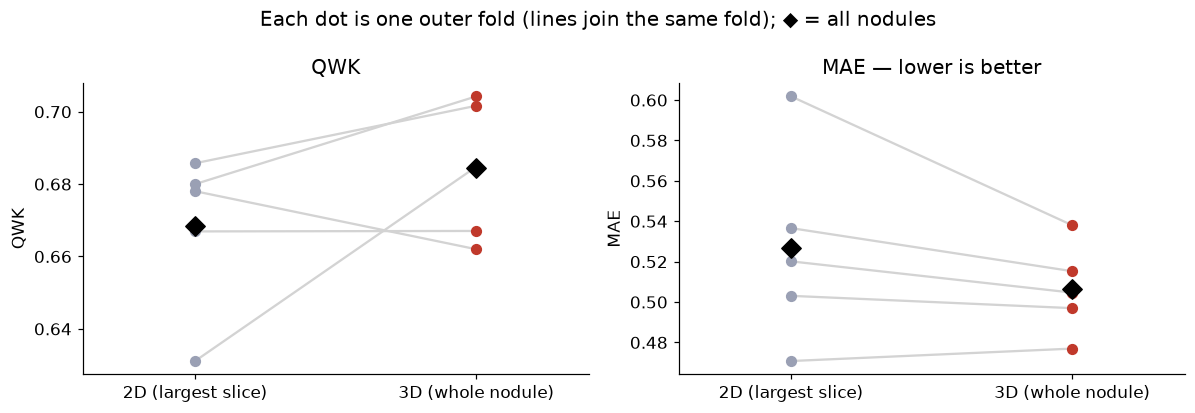

3D better than 2D: QWK in 4/5 folds, MAE in 4/5 folds


In [4]:
per_fold = pd.DataFrame([{'fold': k, 'metric': m,
                           **{arm: metrics(y[fold == k], pred[arm][fold == k])[m] for arm in pred}}
                          for k in range(OUTER_SPLITS) for m in ['QWK', 'MAE']])
per_fold = per_fold.groupby(['metric', 'fold']).first()
wins_qwk = (per_fold.loc['QWK', '3D'] > per_fold.loc['QWK', '2D']).sum()
wins_mae = (per_fold.loc['MAE', '3D'] < per_fold.loc['MAE', '2D']).sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, m in zip(axes, ['QWK', 'MAE']):
    d = per_fold.loc[m]
    for k in d.index:
        ax.plot([0, 1], [d.loc[k, '2D'], d.loc[k, '3D']], color='lightgray', zorder=1)
    for x, arm in enumerate(['2D', '3D']):
        ax.scatter([x] * len(d), d[arm], color=ARM_COLORS[arm], zorder=2, s=40)
        ax.scatter([x], [metrics(y, pred[arm])[m]], marker='D', s=80, color='black', zorder=3)
    ax.set(xticks=[0, 1], xticklabels=['2D (largest slice)', '3D (whole nodule)'], xlim=(-0.4, 1.4),
           title=m + (' — lower is better' if m == 'MAE' else ''), ylabel=m)
fig.suptitle('Each dot is one outer fold (lines join the same fold); ◆ = all nodules')
plt.tight_layout(); plt.show()
print(f'3D better than 2D: QWK in {wins_qwk}/{OUTER_SPLITS} folds, MAE in {wins_mae}/{OUTER_SPLITS} folds')

## 4. Where does 3D make the difference?
The trade-offs in the introduction suggest where 3D should help most (thin slices, which carry real
3D information; larger nodules, which span many slices) and where it might not (thick slices, where
the volume is mostly interpolated). Mean absolute error per group:

In [5]:
groups_def = {
    'Slice thickness': pd.cut(lidc.slice_thickness, [0, 1.5, 2.5, 10], labels=['≤ 1.5 mm', '1.5–2.5 mm', '> 2.5 mm']),
    'Nodule diameter': pd.cut(lidc.diameter_mm, [0, 6, 10, 100], labels=['< 6 mm', '6–10 mm', '≥ 10 mm']),
}
rows = []
for dim, lab in groups_def.items():
    for g in lab.cat.categories:
        m = (lab == g).values
        rows.append({'dimension': dim, 'group': g, 'nodules': int(m.sum()),
                     'MAE 2D': mean_absolute_error(y[m], pred['2D'][m]),
                     'MAE 3D': mean_absolute_error(y[m], pred['3D'][m])})
by_group = pd.DataFrame(rows).set_index(['dimension', 'group'])
by_group['3D gain'] = by_group['MAE 2D'] - by_group['MAE 3D']
by_group.style.format({'nodules': '{:.0f}', 'MAE 2D': '{:.3f}', 'MAE 3D': '{:.3f}', '3D gain': '{:+.3f}'})

## Conclusion
**3D is better than 2D on all four competition metrics**, with the same nodules, segmentation, model
and folds — and consistently so: it wins in **4 of 5 folds** on both QWK and MAE
(QWK 0.685 vs 0.669, MAE 0.506 vs 0.527, balanced accuracy 0.535 vs 0.522, macro F1 0.536 vs 0.523).
The gain is moderate but systematic.

- **It grows with nodule size**: almost none below 6 mm (a small nodule spans only a few slices, so the
  volume adds little), ≈ 0.025 in MAE for 6–10 mm and ≥ 10 mm nodules.
- **It holds for thin and for thick slices** (MAE gain ≈ 0.055 for ≤ 1.5 mm and > 2.5 mm): the risk we
  expected for 3D — interpolating between thick slices — did not materialise. The middle group
  (1.5–2.5 mm, half of the nodules) is a tie (−0.013 in MAE, within fold-to-fold noise), so slice
  thickness does not explain where 3D helps; nodule size does.

Our choice of a 3D pipeline is therefore an **evidence-based design decision**, not only an argument.

In [6]:
shutil.rmtree(CACHE_DIR, ignore_errors=True)    # remove the temporary pipeline cache